## PCA AC 20

This notebook computes historic time series for implied vols, fitting error, DLV vs a gixed NMS grid.



In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.sanos.sanos_tools
%aimport quantdata.sanos.arbfree
%aimport quantdata.sanos.sanos
%aimport quantdata.dysanos.grid.interpolated
%aimport quantdata.dysanos.grid.torch_market
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_model_static
%aimport quantdata.dysanos.grid.torch_model_pca
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 

from quantdata.dysanos.grid.torch_market import GridMarketDefinition, DateRange, PoolConfig, Context, date

grid_market_def = GridMarketDefinition( ticker="SPX", date_range=DateRange(start=date(2020, 1, 1), end=date(2025, 8, 30)) )
market          = grid_market_def.load( pool_config = PoolConfig(num_workers=4, threading=False ), verbose=Context.all )
print(f"nms /done - found {len(market['dates'])} dates.")
    

nms /done - found 1412 dates.


00: Training 20-pca-18-ac-SELU version 0.1 group 'base_sm25' for 200000 epochs on SPX for date range 2020-01-01_2025-08-30x
00: Using batches of 128 samples with learning rate 0.0001 and weight decay 0.0001.
01:   Model config: 20-pca-18-ac-SELU.base_sm25 0.1 0.25-smooth@20@18qr midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=100,a=SELU,b=True),lrn=FF(d=2,w=100,a=SELU,b=True)
01:   Grid config: nms,rg=(-2,1),nm=20,xp=(2.0,4.9,9.9,39.5,126.0,252.0);sth=0.25,mid=0.01,mxd=2
01:   Mk Arb Free pre-processor: surface,mhs=0.0001,mw=0.10,mav=0.05,mik=5,mdn=0.0001,dC=0.001,dps=0.0001
01:   Options filter: nopt=1000,bdte=756,nmsat=(-5.0, 2.0),lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   Raw day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
00: Preparing data set 20-pca-18-ac-SELU version 0.1 on Env(prec=32,device=cuda,debug=False)... done; this took 0.19s.
00: Instantiating 20-pca-18-ac-SELU version 0.1 on Env(prec=32,device=cuda,debug=False)... done;

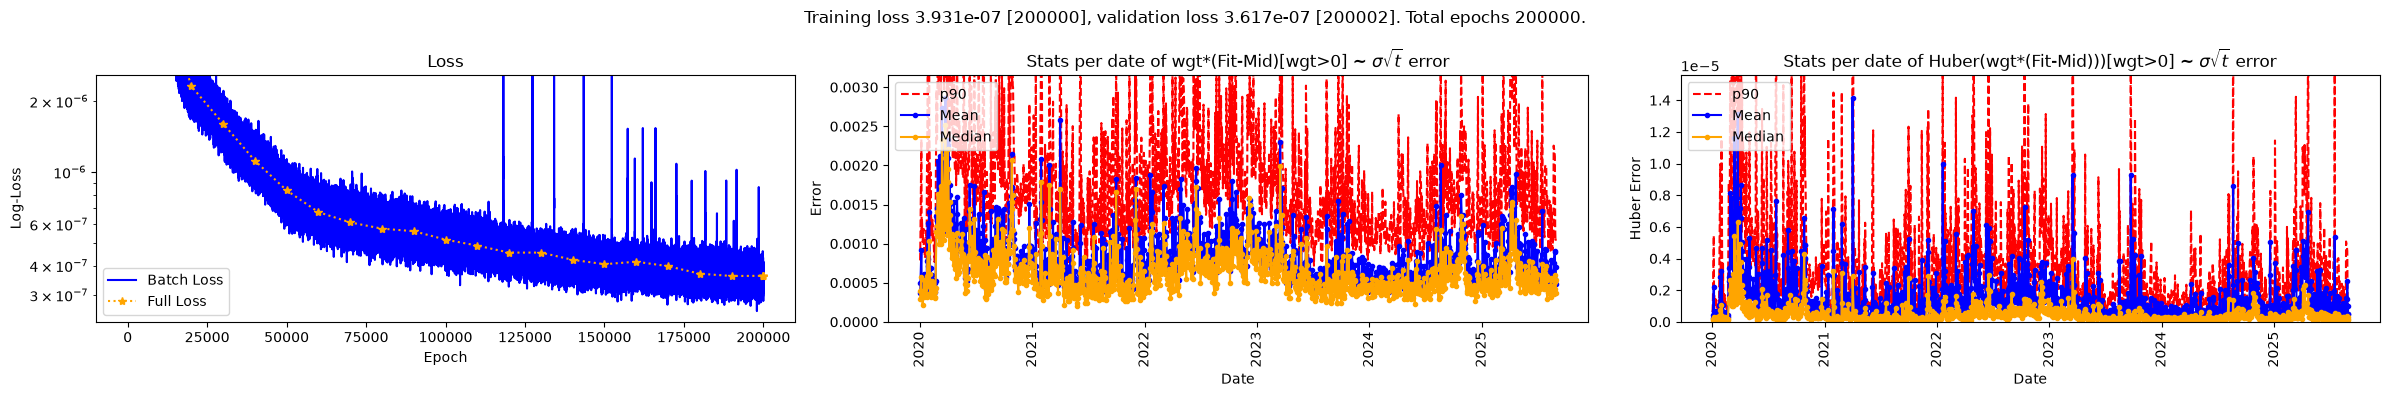

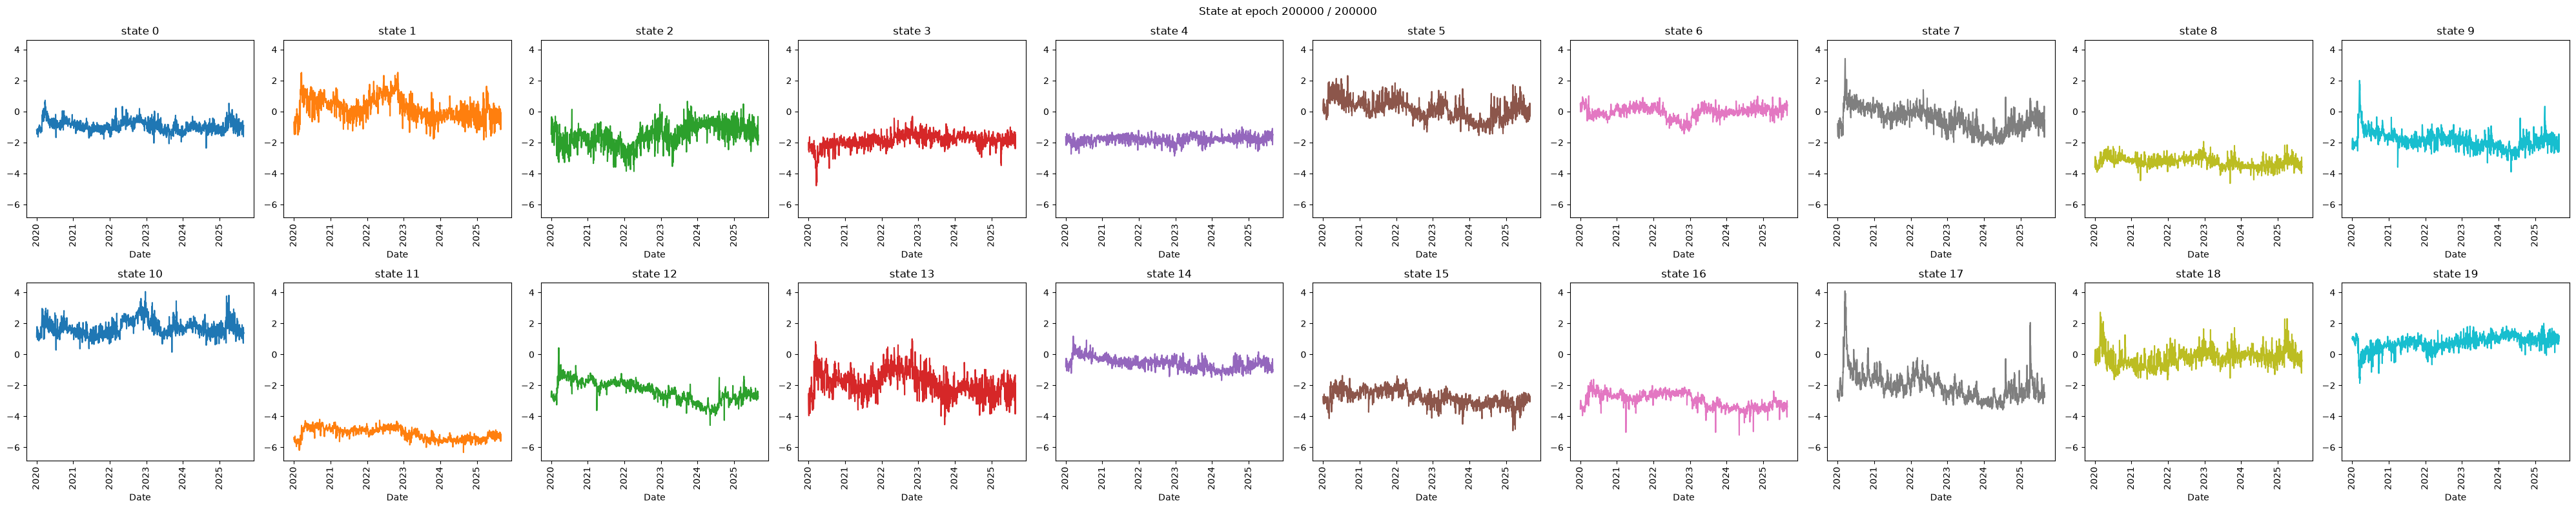

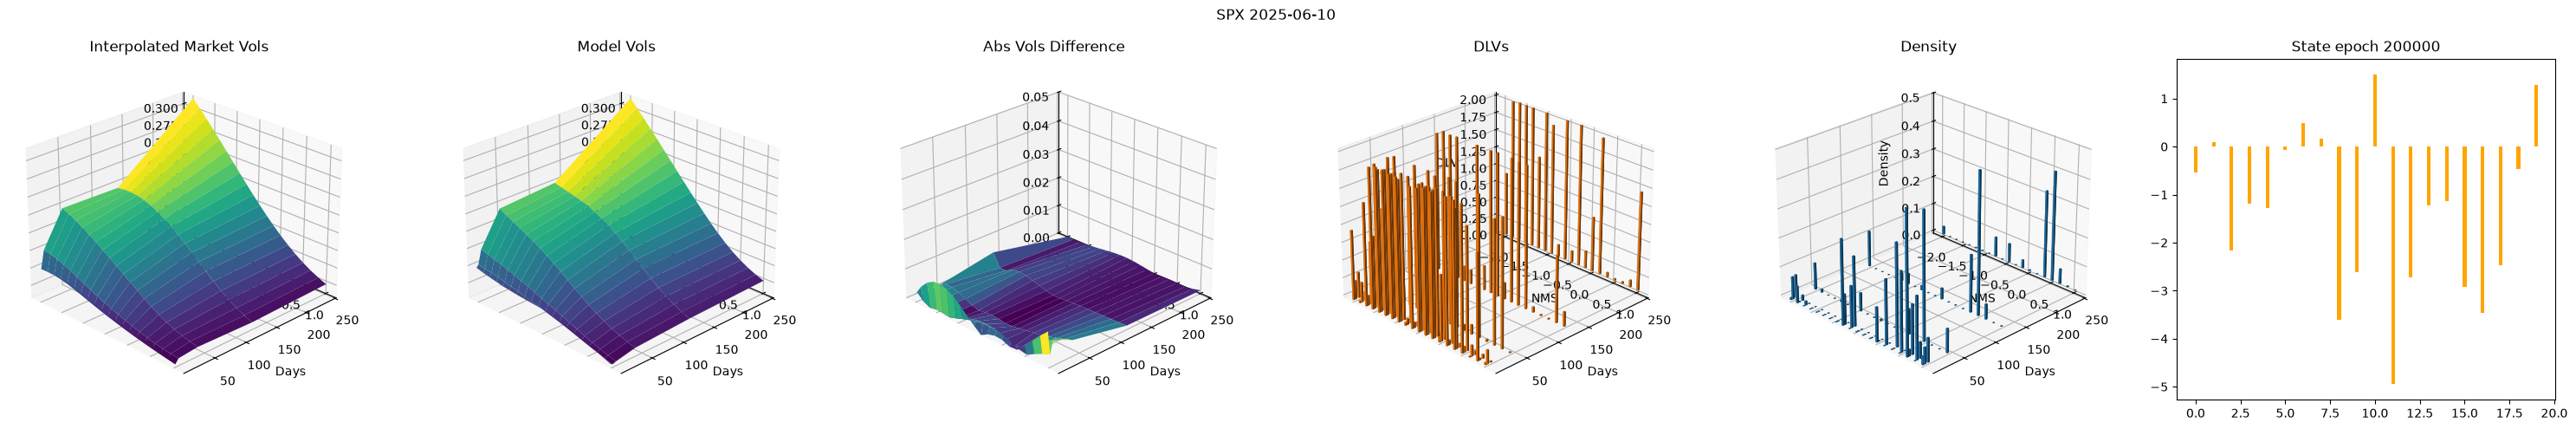

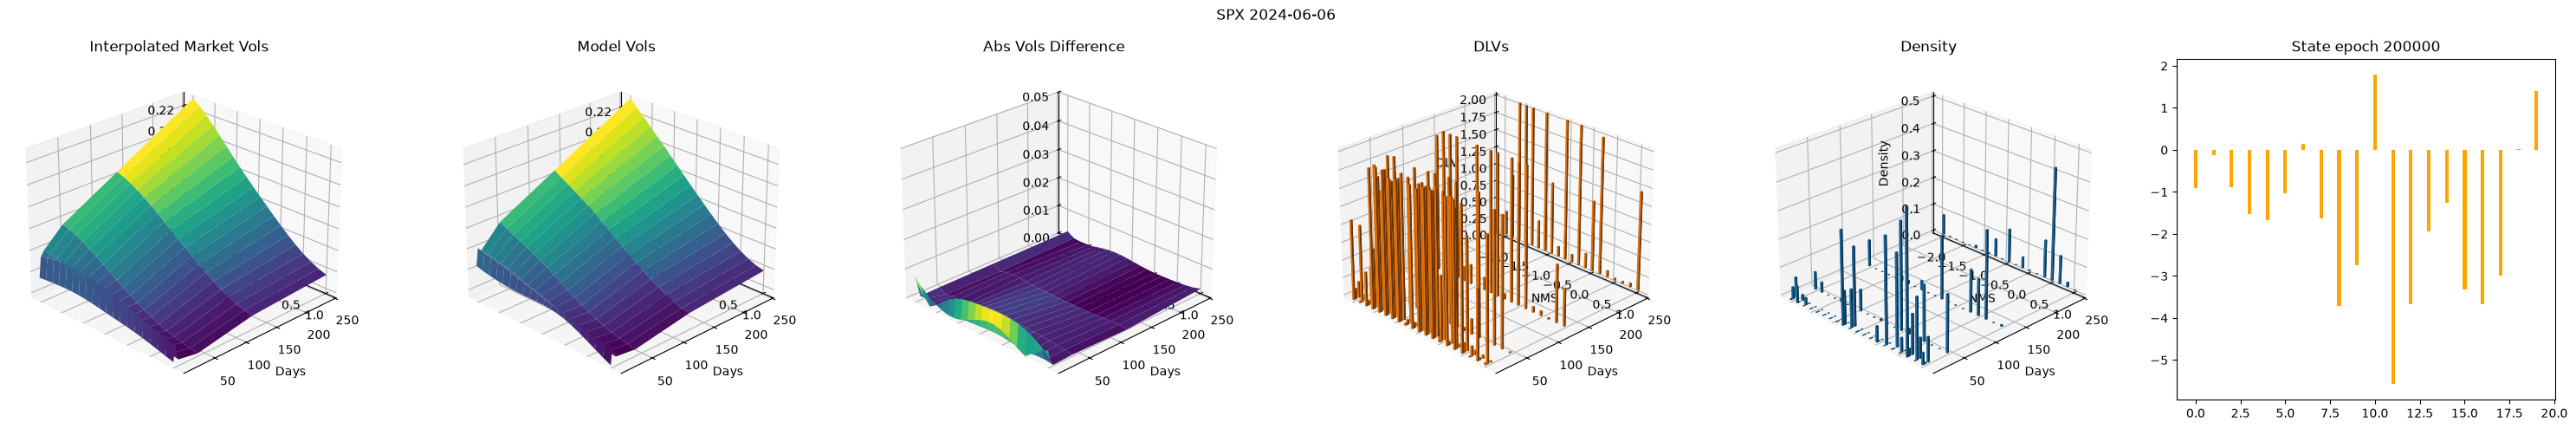

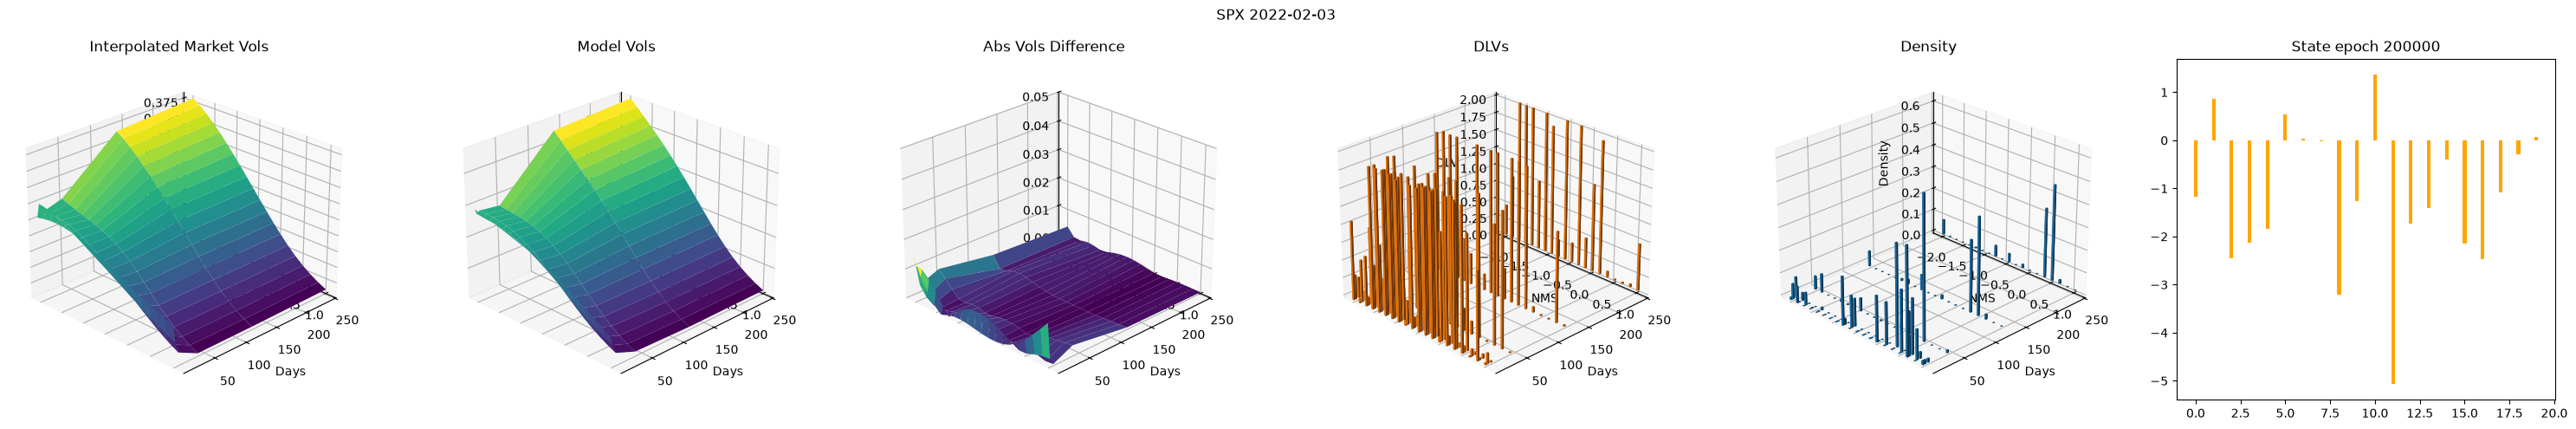

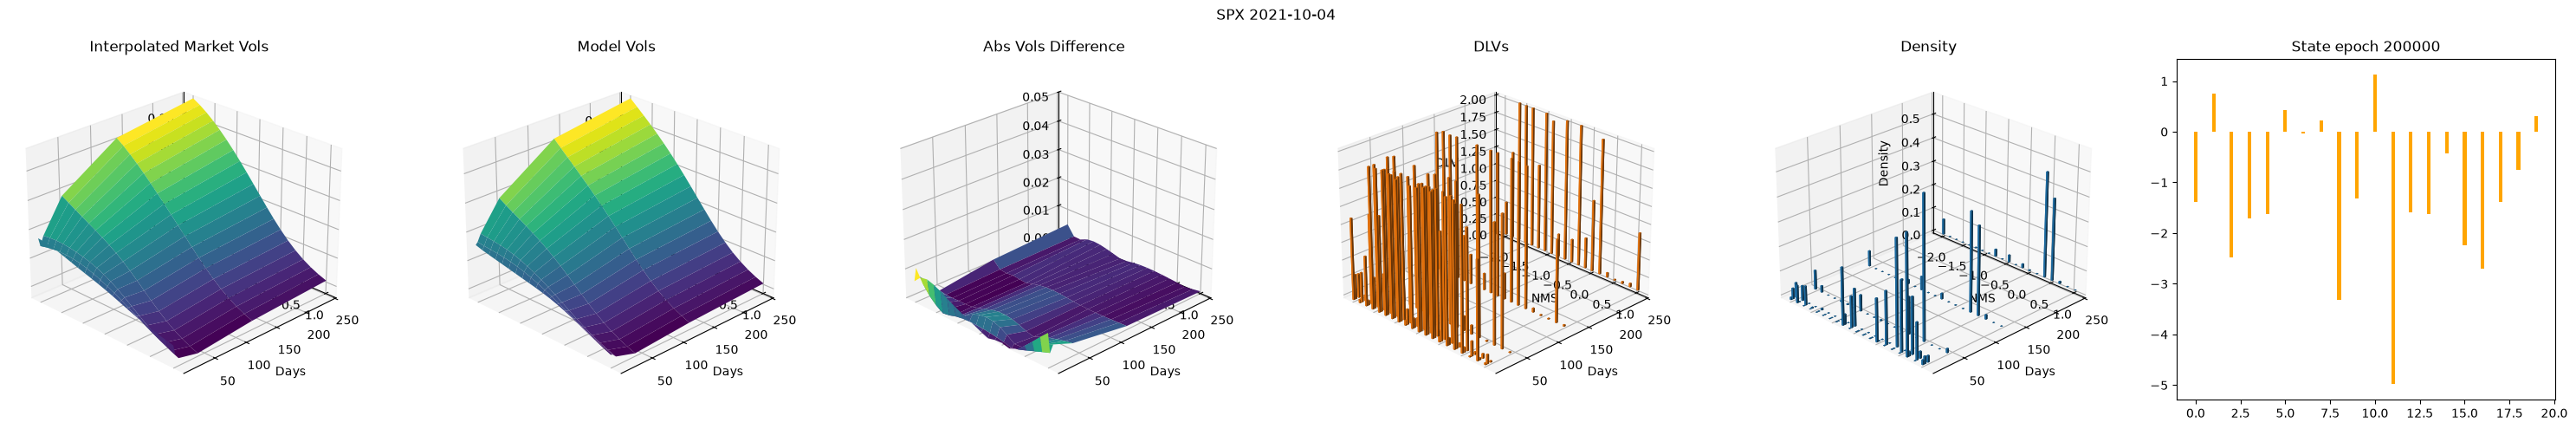

00: Model 20-pca-18-ac-SELU version 0.1 group 'base_sm25' trained for 200000 epochs. Final training loss: 3.931e-07, valuation loss: 3.617e-07. This took 6s.
00: Checkpoint file is /home/hans/.dysanos_grid/base_sm25/20-pca-18-ac-SELU.pt.
/done


In [3]:
from cdxcore.dynaplot import FigStore, colors_tableau, figure, m_o_m
from quantdata.pool import PoolConfig
from quantdata.dysanos.grid.torch_gfx import VizConfig
from quantdata.dysanos.grid.torch_train import train, TrainConfig
from quantdata.dysanos.grid.torch_model_pca import BaseEnvironment, FeedForward, SanosPCACompressorConfig
import numpy as np

mdl_config = SanosPCACompressorConfig( 
    group="base_sm25",
    user_version="0.1",
    smoothness = 0.25,
    num_state = 20, 
    num_pca = 18,
    use_qr = True,
    state_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
    learn_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
)
viz_config = VizConfig( num_viz_dates=4 )
trn_config = TrainConfig( num_epochs=200000, lr=1E-4, weight_decay=1e-4, batch_size=128, compile=True, epoch_interval=10000 )
r, model, tdata = train( market, mdl_config=mdl_config, trn_config=trn_config, viz_config=viz_config )
print("/done")


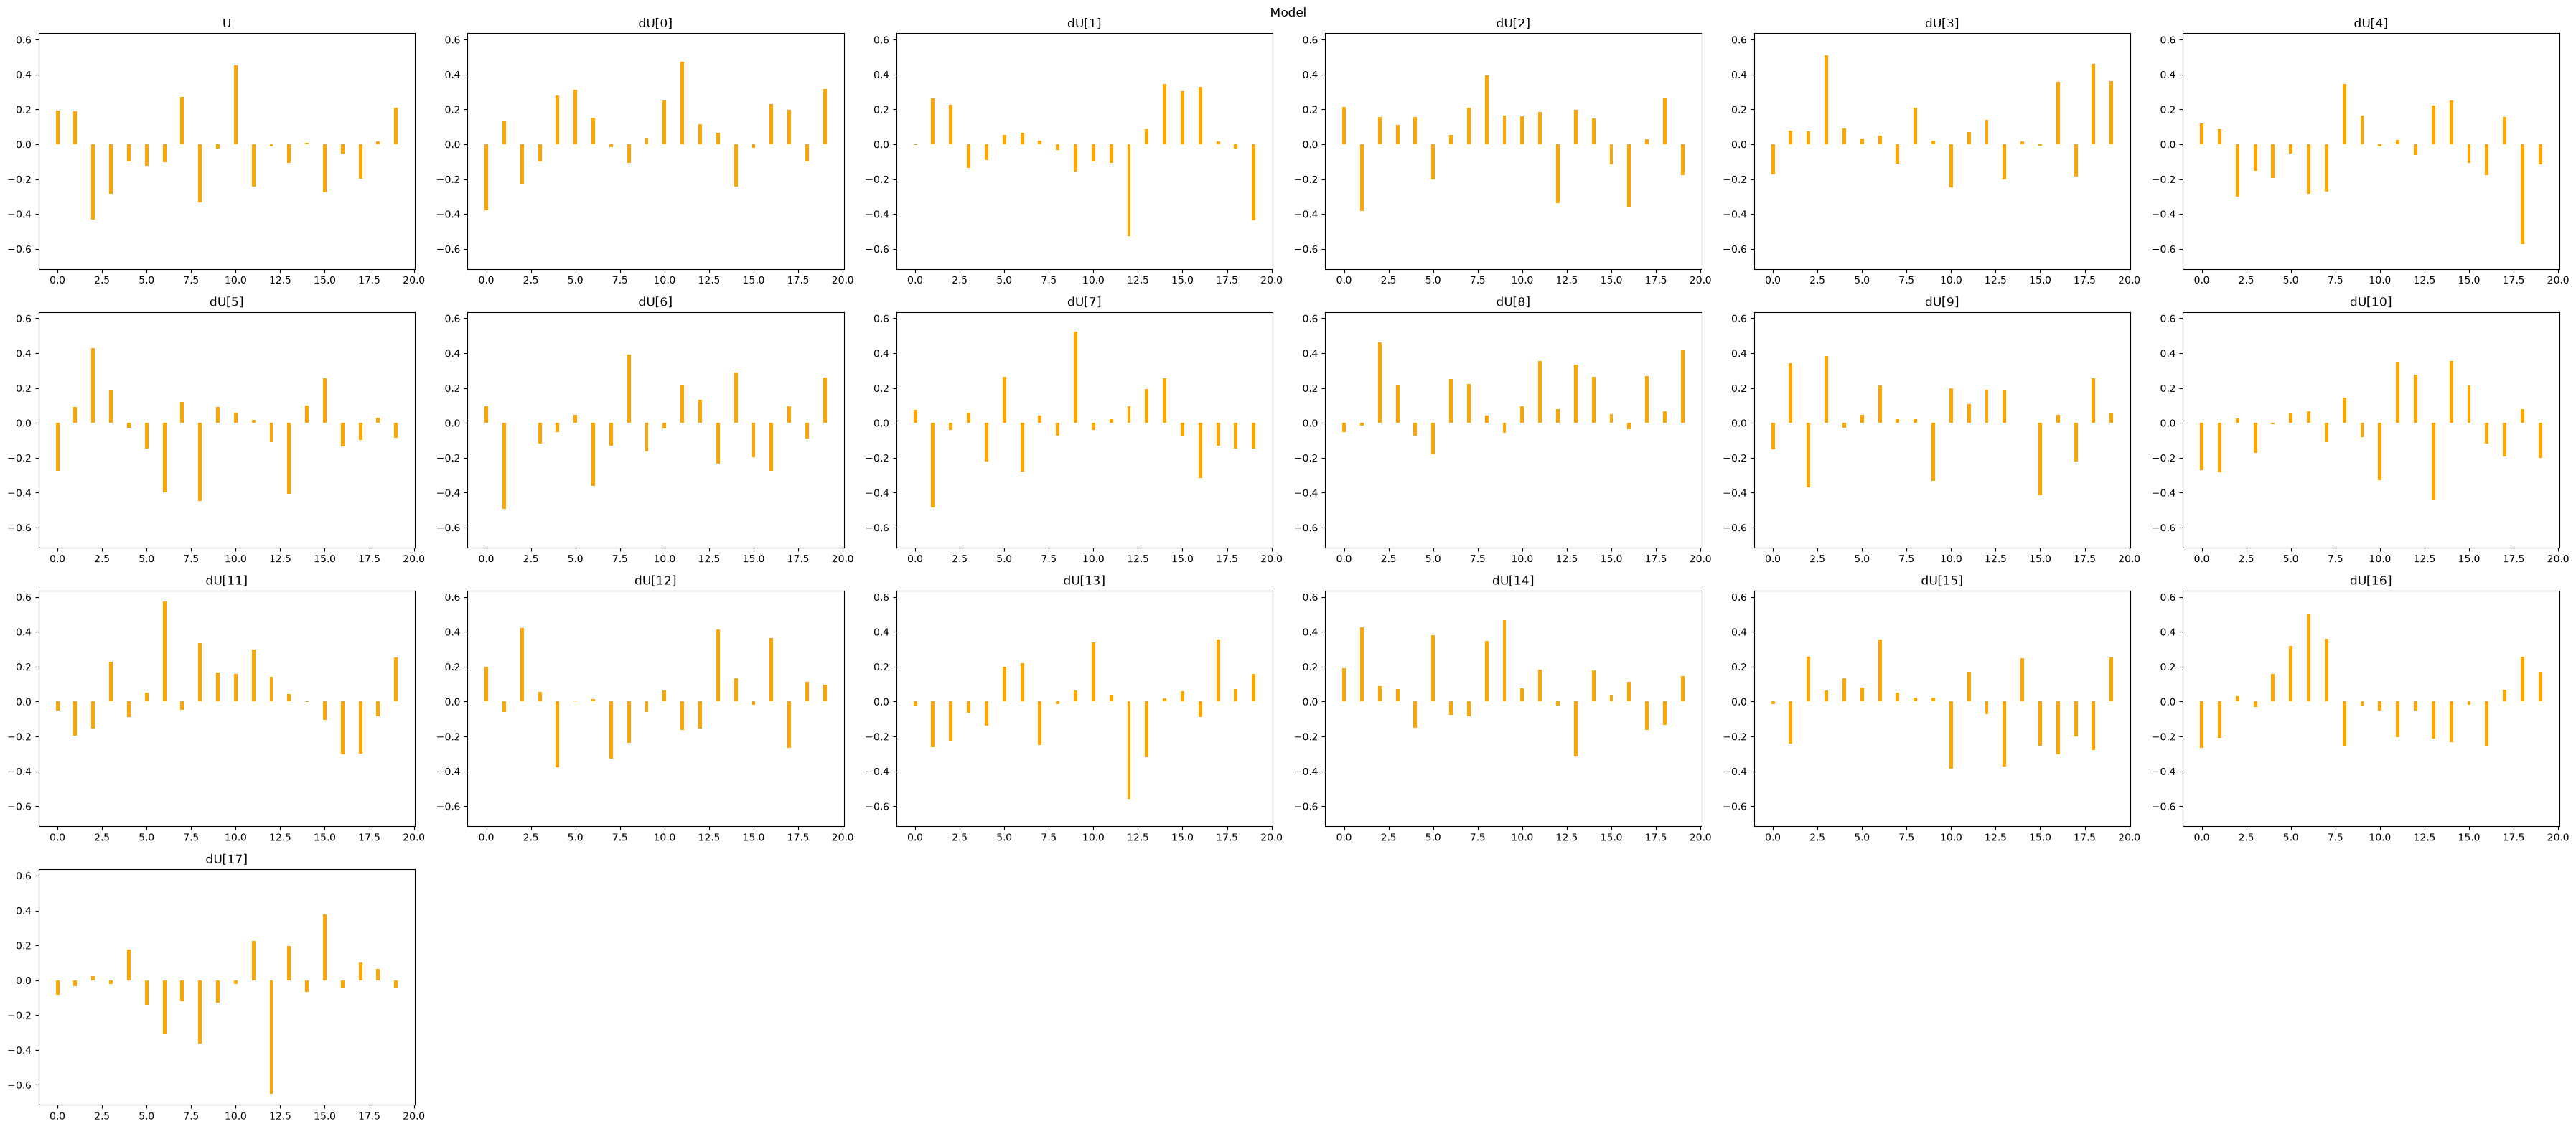

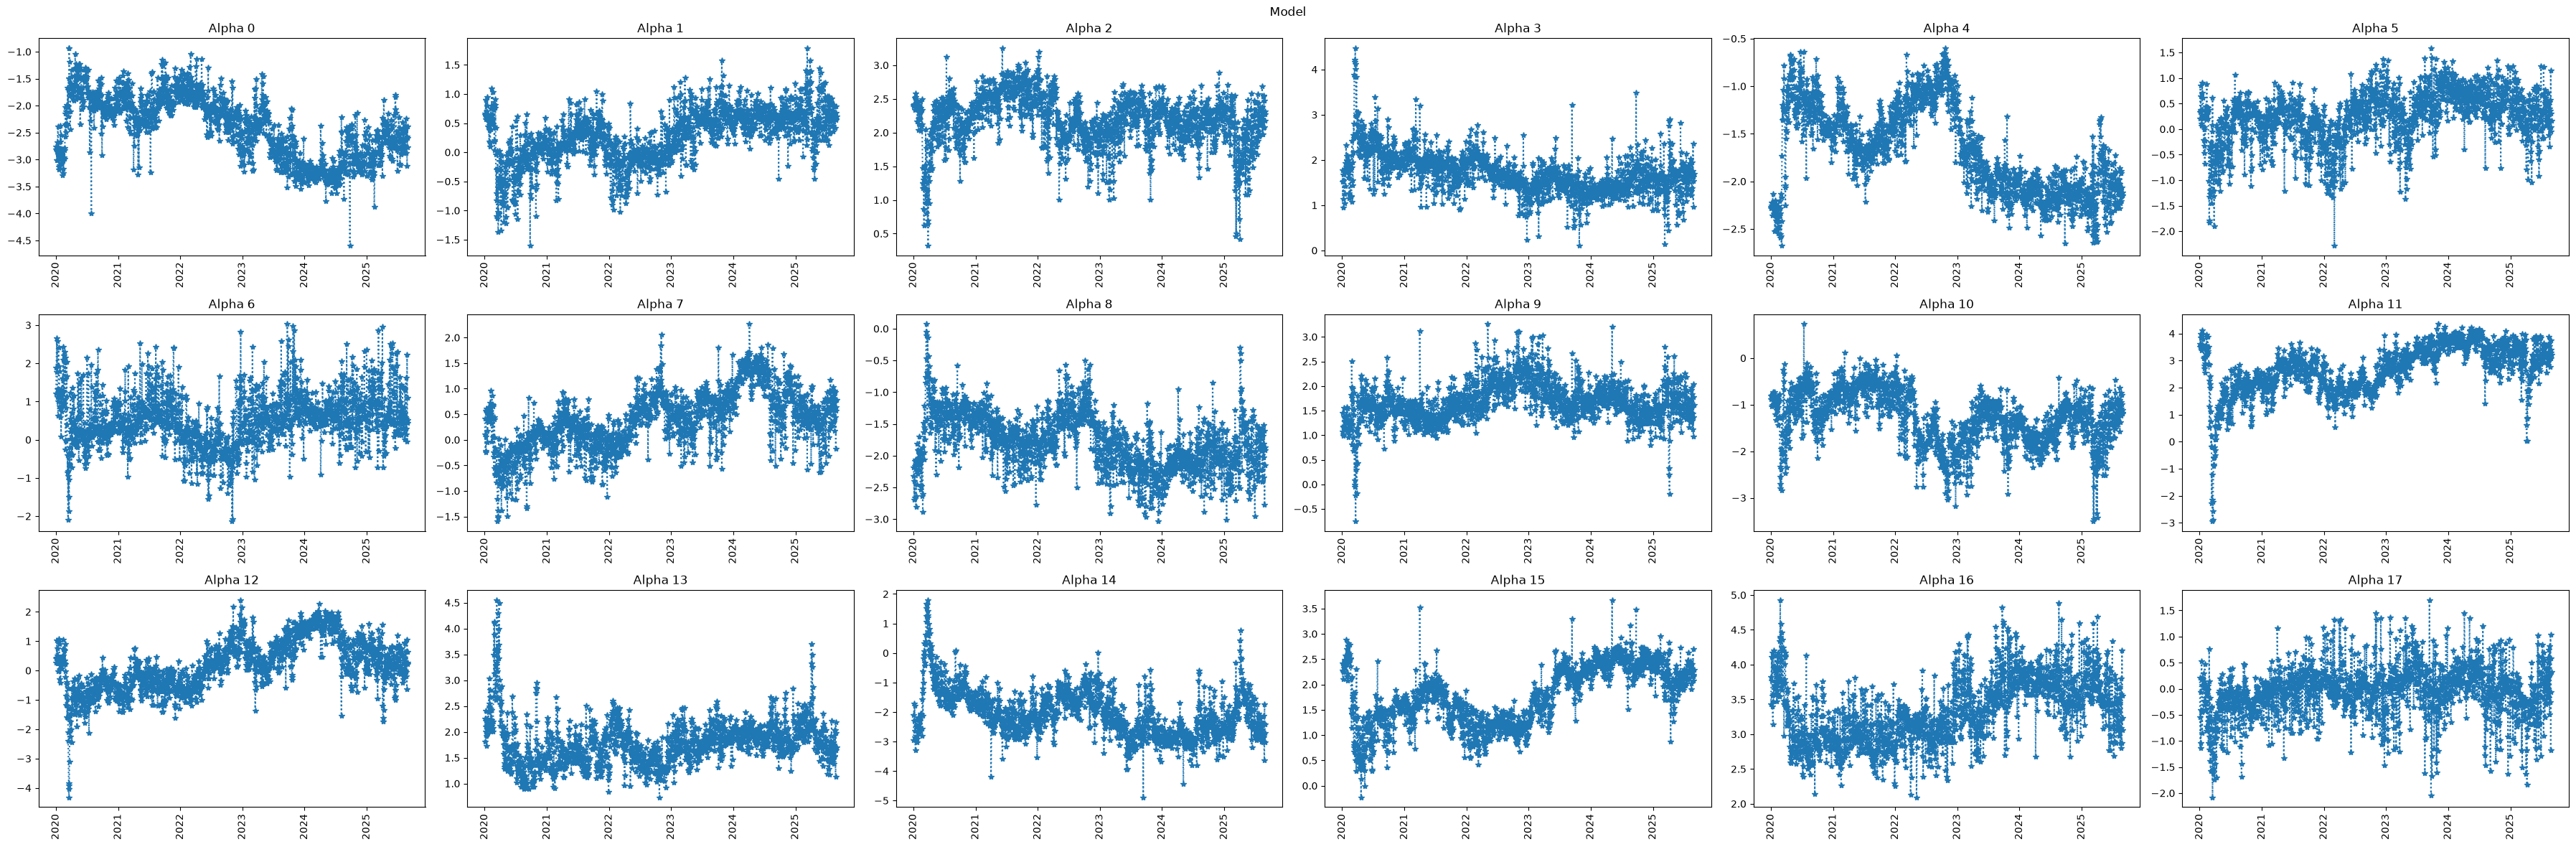

In [25]:
from cdxcore.dynaplot import figure, colors_tableau
import numpy as np

def plot_stuff(*,draw_states=False,draw_alpha=True,draw_u_du=True,pca=False):
    dates = market.dates
    ld = model(tdata, training=False)
    ld = { k: v.detach().cpu().numpy() for k, v in ld.items() }
    u_du = model.u_du.detach().cpu().numpy()

    state = ld['state']
    alpha = ld['alpha']

    T         = len(dates)
    num_state = state.shape[-1]
    num_alpha = alpha.shape[-1]
    
    u  = u_du[0,:][None,:]
    du = u_du[1:,]
    if model.config.use_qr:
        duT, _ = np.linalg.qr(du.T,mode="reduced")
        du = duT.T
        del duT
    manual_state = u + alpha @ du
    assert manual_state.shape == state.shape
    assert state.shape[0] == T

    # manual PCA
    if pca:
        def pca_():
            mu0    = np.mean(state, axis=0, keepdims=True)
            Xc     = state - mu0
            U, SD, Vt = np.linalg.svd(Xc, full_matrices=False)
            mdu   = Vt[:num_alpha]               # shape (K, M), orthonormal rows
            assert mdu.shape == (num_alpha,num_state)
            alpha2 = U[:, :num_alpha] * SD[:num_alpha]     # shape (T, num_alpha)
            return alpha2, np.concatenate( [mu0, mdu], axis=0 )
        malpha, mu_du = pca_()
    
    if draw_u_du:
        def draw(label, u_du):
            with figure(label, row_size=4, col_size=6, columns=6 ) as fig:
                ax_ = None
                for i in range(u_du.shape[0]):
                    ax = fig.add_subplot("U" if i==0 else f"dU[{i-1}]")
                    ax.bar( np.arange(u_du.shape[1]), u_du[i,:]/np.linalg.norm(u_du[i,:]), width=0.2, color="orange")
                    if not ax_ is None:
                        ax.sharey(ax_)
                    ax_ = ax
        draw("Model", u_du)
        if pca: draw("PCA", mu_du)
    
    if draw_alpha:
        def draw( label, alpha ):
            with figure(label, row_size=4, col_size=6, columns=6 ) as fig:
                for i in range(alpha.shape[1]):
                    ax = fig.add_subplot(f"Alpha {i}")
                    ax.plot( dates, alpha[:,i], "*:", label="Model")
                    ax.tick_params(axis="x", labelrotation=90)
        draw("Model", alpha)
        if pca: draw("PCA", malpha)

    if draw_states:
        with figure("States", row_size=4, col_size=6, columns=6 ) as fig:
            for i in range(manual_state.shape[1]):
                ax = fig.add_subplot(f"State {i}")
                ax.plot( dates, state[:,i], "*:", label="Model")
                ax.plot( dates, manual_state[:,i], label="Manual")
                ax.tick_params(axis="x", labelrotation=90)
                ax.legend(loc="upper left")


plot_stuff()


